# Kode 3.1 Statistik dan histogram untuk diagnosis 

In [3]:
from pathlib import Path
import sys

root = Path.cwd()
if not (root / "src" / "utils_cv.py").exists():
    root = root.parent

sys.path.insert(0, str(root / "src"))
print(Path.cwd())

c:\Users\Lenovo\Documents\GitHub\SIMUTEH-2330511060\notebook


teh_045.png {'rerata': 125.8, 'simpangan_baku': 52.7, 'min': 29, 'maks': 237, 'persen_gelap': 1.2, 'persen_terang': 7.6}


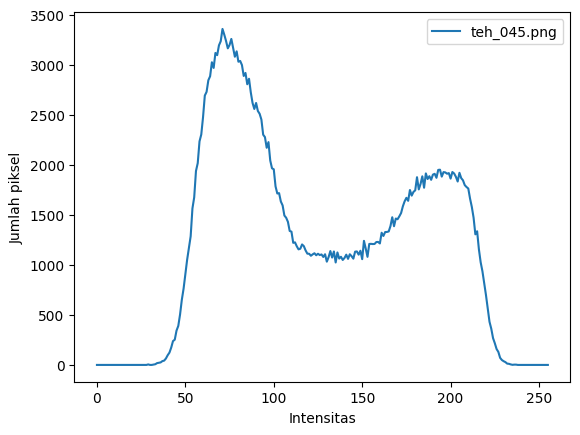

In [4]:
import cv2 
import matplotlib.pyplot as plt
from utils_cv import baca, kontras_bercak, statistik 

for nama in ["teh_041.png", "teh_042.png", "teh_043.png", 
"teh_044.png", "teh_045.png"]: 
    gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"), 
    cv2.COLOR_BGR2GRAY) 
print(nama, statistik(gray)) 
hist = cv2.calcHist([gray], [0], None, [256], [0, 256]) 
plt.plot(hist, label=nama) 
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend() 
plt.savefig("../hasil/b3_histogram_5kondisi.png") 

# Kode 3.2 Operasi titik, peregangan, gamma, ekualisasi, dan CLAHE 

In [5]:
import numpy as np

nama = "teh_045.png"                 # kondisi bayangan 
img = baca(f"../data/sintetis/citra/{nama}") 
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0) 
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0) 
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) 
  
def gamma_lut(g): 
    lut = np.array([255 * (i / 255) ** g for i in range(256)]) 
    return lut.clip(0, 255).astype(np.uint8) 
  
rmin, rmax = np.percentile(gray, (2, 98))      # abaikan 2% piksel ekstrem 
hasil = { 
    "asli": gray, 
    "negatif": 255 - gray, 
    "cerah+50": cv2.add(gray, 50), 
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40), 
    "regang": np.clip((gray - rmin) / (rmax - rmin) * 255, 
                      0, 255).astype(np.uint8), 
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)), 
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)), 
    "ekualisasi": cv2.equalizeHist(gray), 
    "CLAHE": cv2.createCLAHE(clipLimit=2.0, 
                             tileGridSize=(8, 8)).apply(gray), 
} 
for nm, c in hasil.items(): 
    print(f"{nm:10s} KB={kontras_bercak(c, md, mb):.2f} " 
          f"sigma={c.std():.1f}") 


asli       KB=1.03 sigma=52.7
negatif    KB=1.03 sigma=52.7
cerah+50   KB=1.03 sigma=51.7
kontras    KB=1.03 sigma=75.6
regang     KB=1.06 sigma=81.5
gamma0.5   KB=0.94 sigma=37.9
gamma1.8   KB=1.19 sigma=56.4
ekualisasi KB=0.85 sigma=73.4
CLAHE      KB=1.91 sigma=44.4
